[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L5/BA_L5_ew_tradeoff/BA_L5_ew_tradeoff.ipynb)

# BA_L5_ew_tradeoff: Recall against False Alerts of a Price-Only Alarm

*Quantlet of Lecture 5, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Timely event recall against false-alert episodes per month for price-only early-warning alarms of a 15 basis point breach of USDC priced in USDT (a threshold rule, a logistic regression and gradient boosting), on the test period 2 January 2025 to 23 October 2026; trained on 2022-2023 hourly data. Data: EODHD hourly prices.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Setup: chart style and colours of the slides, and a `save()` helper that puts one legend below the figure.

In [4]:
import matplotlib
import matplotlib.dates as mdates
from scipy import stats

# the slide charts use matplotlib's default sizes with 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 'medium', 'axes.titlesize': 'large', 'axes.linewidth': 0.8,
                     'lines.linewidth': 1.5, 'legend.fontsize': 8})
COL = {'USDT': GREEN, 'USDC': BLUE, 'DAI': GOLD}


def save(fig, name, bottom, ncol=3):
    """One legend for all panels below the plot (as on the slide), then save to OUT_PATH and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

## What the chart shows

The target is a breach of $\delta = 15$ basis points (bp) by USDC priced in USDT, $d_t = 10^4(P^{\mathrm{USDC}}_t / P^{\mathrm{USDT}}_t - 1)$, within the next 24 hours:

$$ y_t = \mathbb 1\Big\{\max_{1 \leq h \leq 24} |d_{t+h}| \geq \delta\Big\}. $$

An **event** starts at a breach hour preceded by 24 observed hours without a breach; a breach after a quiet spell that contains missing hours is ambiguous and set aside.
An alarm is scored per event: alerts closer than 24 hours are merged, an event is detected if an alert falls 1 to 24 hours before it, and every other alert episode is false.

Three price-only alarms are compared on the test period, 2 January 2025 to 23 October 2026:

- a rule $|d_t| \geq k$ for $k = 4, \dots, 14$ bp;
- a logistic regression on standardised features and a gradient-boosting classifier, trained on 2022–2023, with features $d_t$, $|d_t|$, the 24-hour maximum of $|d|$, the 24-hour volatility of $\Delta d$, the deviation from the 168-hour mean, DAI and USDT against the US dollar (USD), and the 24-hour return and annualised volatility of Bitcoin (BTC).

Each curve traces every threshold on the test period (a diagnostic only, since the test data set the threshold). The star is the best model of the paper, CatBoost with on-chain features, from Table 1 of Chaffard, Găman, Staures, Ginavar, Jheng, Härdle & Pele (2026), *Onchain Monitoring of Stablecoin Depeg Risk*, working paper, estimated on another sample.

**Data:** EOD Historical Data (EODHD) hourly closing prices of USDC, USDT, DAI and BTC, January 2022 to 23 October 2026.

In [5]:
H = pd.concat({'USDC': hourly('USDC-USD.CC'), 'USDT': hourly('USDT-USD.CC'), 'DAI': hourly('DAI-USD.CC'),
               'BTC': hourly('BTC-USD.CC')}, axis=1)
H = H.reindex(pd.date_range('2022-01-01 00:00', '2026-10-23 23:00', freq='h'))   # regular hourly grid, lecture sample
dh = 1e4 * (H['USDC'] / H['USDT'] - 1)                                             # USDC priced in USDT, bp
print(f'hourly grid: {H.index[0]} to {H.index[-1]} UTC, {len(H)} hours; '
      f'hours with USDC or USDT missing: {100 * H[["USDC", "USDT"]].isna().any(axis=1).mean():.2f}%')

def episodes(dd, th, quiet=24, ambiguous=False):
    """Episode starts: breach hours (|d| >= th) preceded by `quiet` hours that are all observed and below th.
    With ambiguous=True also returns the breach hours after a quiet spell that contains missing hours."""
    b = dd.abs() >= th
    valid = dd.notna()
    q = (valid & ~b).astype(float).rolling(quiet).sum().shift(1) == quiet
    start = b & valid & q
    if not ambiguous:
        return dd.index[start]
    nobreach = b.astype(float).rolling(quiet).sum().shift(1) == 0
    return dd.index[start], dd.index[b & valid & ~q & nobreach]

def v(l):
    """Credit for the first valid alert with a lead of l hours."""
    l = np.asarray(l, dtype=float)
    return np.where((l >= 1) & (l <= 24), 0.10 + 0.90 * (l - 1) / 23, 0.0)

hourly grid: 2022-01-01 00:00:00 to 2026-10-23 23:00:00 UTC, 42168 hours; hours with USDC or USDT missing: 2.80%


In [6]:
# label: a 15 bp breach in t+1..t+24, defined only when all 24 future hours are observed
fut_b = (dh.abs() >= 15).astype(float)[::-1].rolling(24, min_periods=24).max()[::-1].shift(-1)
fut_n = dh.notna().astype(float)[::-1].rolling(24, min_periods=24).sum()[::-1].shift(-1)
y24 = fut_b.where(fut_n == 24)

F = pd.DataFrame(index=H.index)
F['d'] = dh
F['absd'] = dh.abs()
F['max24'] = dh.abs().rolling(24, min_periods=12).max()
F['sd24'] = dh.diff().rolling(24, min_periods=12).std()
F['dev168'] = dh - dh.rolling(168, min_periods=84).mean()
F['dai'] = 1e4 * (H['DAI'] - 1)
F['usdt'] = 1e4 * (H['USDT'] - 1)
rb = np.log(H['BTC']).diff()
F['btcvol24'] = rb.rolling(24, min_periods=12).std() * np.sqrt(24 * 365) * 100
F['btcret24'] = 100 * (np.log(H['BTC']) - np.log(H['BTC']).shift(24))
F['y'] = y24
FX = F.drop(columns='y').dropna()                     # every hour with features: the alarm is scored here
F = F.dropna()                                         # hours with a complete label: training
tr = F.loc[:'2023-12-30 23:00']; te = FX.loc['2025-01-02':]     # 24-hour embargo before the test period
cols = [c for c in F if c != 'y']
ev_all, ev_amb = episodes(dh, 15, ambiguous=True)


def evaluate(score, thr):
    """Alert episodes (24 h refractory), event credit in [tau - 24h, tau - 1h], false alerts per month, utility U."""
    a = score.index[score.values >= thr]
    alerts, last = [], None
    for t_ in a:
        if last is None or (t_ - last) >= pd.Timedelta(hours=24):
            alerts.append(t_); last = t_
    alerts = pd.DatetimeIndex(alerts)
    evs = ev_all[(ev_all >= score.index[0] + pd.Timedelta(hours=24)) & (ev_all <= score.index[-1])]
    used, leads = set(), []
    for tau in ev_amb:                 # alerts before an ambiguous onset are neither credited nor counted as false
        used.update(alerts[(alerts >= tau - pd.Timedelta(hours=24)) & (alerts <= tau - pd.Timedelta(hours=1))])
    for tau in evs:
        win = alerts[(alerts >= tau - pd.Timedelta(hours=24)) & (alerts <= tau - pd.Timedelta(hours=1))]
        if len(win):
            leads.append((tau - win[0]) / pd.Timedelta(hours=1)); used.update(win)
        else:
            leads.append(0)
    months = (score.index[-1] - score.index[0]) / pd.Timedelta(days=30.44)
    fa = len([a_ for a_ in alerts if a_ not in used]) / months
    leads = np.array(leads)
    det = leads > 0
    return {'events': len(evs), 'detected': int(det.sum()), 'recall': det.mean() if len(evs) else np.nan,
            'median lead (h)': float(np.median(leads[det])) if det.any() else np.nan,
            'false alerts per month': fa, 'utility U': (v(leads).mean() if len(leads) else 0) - 0.05 * fa}

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

models = {'logistic': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.5)),
          'gradient boosting': HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300, random_state=0)}
curve = {}
for name, mdl in models.items():
    mdl.fit(tr[cols], tr['y'])
    st = pd.Series(mdl.predict_proba(te[cols])[:, 1], index=te.index)
    curve[name] = [evaluate(st, q) for q in np.unique(np.quantile(st, np.linspace(0.90, 0.999, 40)))]
KS = list(range(4, 15))
naive = pd.Series(te['absd'].values, index=te.index)
curve['rule'] = [evaluate(naive, k) for k in KS]

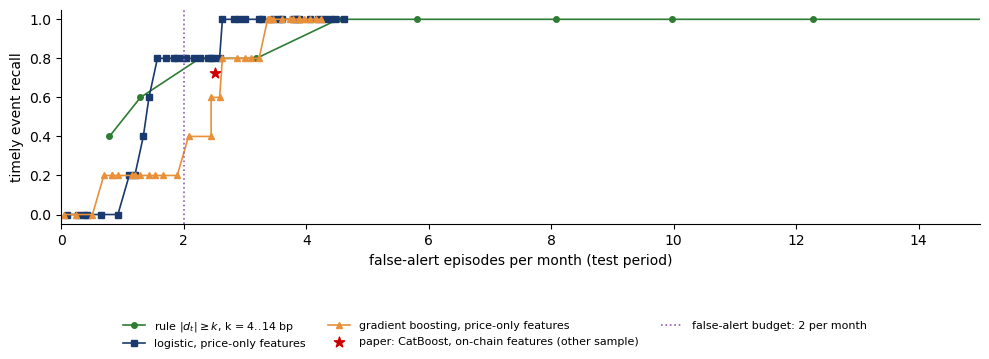

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.6))
labels = {'rule': 'rule $|d_t| \\geq k$, k = 4..14 bp', 'logistic': 'logistic, price-only features',
          'gradient boosting': 'gradient boosting, price-only features'}
for name, col, mk in [('rule', GREEN, 'o'), ('logistic', BLUE, 's'), ('gradient boosting', BTC, '^')]:
    c = pd.DataFrame(curve[name])
    ax.plot(c['false alerts per month'], c['recall'], color=col, marker=mk, ms=4, lw=1.2, label=labels[name])
ax.scatter([2.50], [0.723], color=RED, s=60, marker='*', zorder=6, label='paper: CatBoost, on-chain features (other sample)')
ax.axvline(2, color=ETH, ls=':', lw=1.2, label='false-alert budget: 2 per month')
ax.set_xlabel('false-alert episodes per month (test period)'); ax.set_ylabel('timely event recall'); ax.set_xlim(0, 15)
save(fig, 'ba_l5_ew_tradeoff', 0.2, ncol=3)

## Key numbers: the rule $|d_t| \geq k$ on the test period

In [9]:
RULE = pd.DataFrame(curve['rule'], index=pd.Index(KS, name='rule threshold k (bp)'))
print(RULE[['events', 'detected', 'recall', 'median lead (h)', 'false alerts per month', 'utility U']].round(3).to_string())
k_, n_ = 4, 5
lo_cp, hi_cp = stats.beta.ppf(0.025, k_, n_ - k_ + 1), stats.beta.ppf(0.975, k_ + 1, n_ - k_)
print(f'\nrecall {k_}/{n_} = {k_ / n_:.2f}; exact (Clopper-Pearson) 95% interval [{lo_cp:.2f}, {hi_cp:.2f}]')

                       events  detected  recall  median lead (h)  false alerts per month  utility U
rule threshold k (bp)                                                                              
4                           5         5     1.0              7.0                  19.511     -0.570
5                           5         5     1.0              5.0                  15.728     -0.428
6                           5         5     1.0              4.0                  12.269     -0.247
7                           5         5     1.0              3.0                   9.963     -0.249
8                           5         5     1.0             21.0                   8.072      0.236
9                           5         5     1.0              9.0                   5.812      0.185
10                          5         5     1.0              9.0                   4.520      0.085
11                          5         4     0.8             20.5                   3.183      0.422


**How to read it:** up and to the left is better. Below the budget of 2 false alerts a month, none of the price-only alarms warns in time before the test events.
With hindsight, the rule $|d_t| \geq 11$ bp detects 4 of the 5 test events with a median lead of 20.5 hours, but with about 3.2 false alerts a month and with $k$ chosen on the test data.
With five events the recall is very uncertain: the exact 95% interval for 4 of 5 runs from about 0.28 to 0.99.